# Randomized Trotter と qDRIFT：誤差スケーリングと可視化

共通の1量子ビット Hamiltonian
$$
H=0.9X+0.5Y+0.2Z,\qquad |\psi_0\rangle=|0\rangle
$$
について、固定順序 Lie--Trotter、各区間で順序を一様ランダム化する randomized Lie--Trotter、qDRIFT を比較する。誤差は固定入力状態に対するトレースノルム $\|\rho-\sigma\|_1$ で測る。

スケーリング曲線の確率的手法は有限標本ではなく、候補 unitary channel を各 step で**厳密に平均**している。アニメーションでは、それとは別に単一ランダム回路と有限標本の分布も表示する。

In [1]:
from pathlib import Path
import sys
import numpy as np
from IPython import get_ipython
ip = get_ipython()
if ip is not None:
    ip.run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

HERE = Path.cwd()
if HERE.name != "randomized_hamiltonian_simulation" and (HERE / "randomized_hamiltonian_simulation").is_dir():
    HERE = HERE / "randomized_hamiltonian_simulation"
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))

import quantum_utils as qu
import randomized_trotter as rt
import qdrift as qd

plt.rcParams.update({
    "figure.figsize": (7.0, 4.6),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

SEED = 20260925
h = np.array([0.9, 0.5, 0.2])
terms = h[:, None, None] * qu.PAULIS
H = np.sum(terms, axis=0)
psi0 = np.array([1.0, 0.0], dtype=complex)
rho0 = qu.density(psi0)
fixed_order = (1, 0, 2)  # Y -> X -> Z
hamiltonian_axis = h / np.linalg.norm(h)

lam, qdrift_probabilities, _ = qd.qdrift_distribution(h)
print(f"lambda = {lam:.3f}")
print("qDRIFT probabilities:", {
    str(label): round(float(probability), 6)
    for label, probability in zip(qu.PAULI_LABELS, qdrift_probabilities)
})

lambda = 1.600
qDRIFT probabilities: {'X': 0.5625, 'Y': 0.3125, 'Z': 0.125}


## 固定時間での誤差スケーリング

固定した $t=1.6$ で step 数を増やす。横軸は各手法が定義する step 数であり、Lie 系では1 step に3個の指数演算、qDRIFT では1個を使う。そのため、この図は漸近スケーリングの比較であって、同じ gate 数に正規化したコスト比較ではない。

qDRIFT の点線は project note と同じ規約の channel bound
$$
\frac{4\lambda^2t^2}{N}\exp\left(\frac{2\lambda|t|}{N}\right)
$$
である。状態誤差はこの上界以下になる。

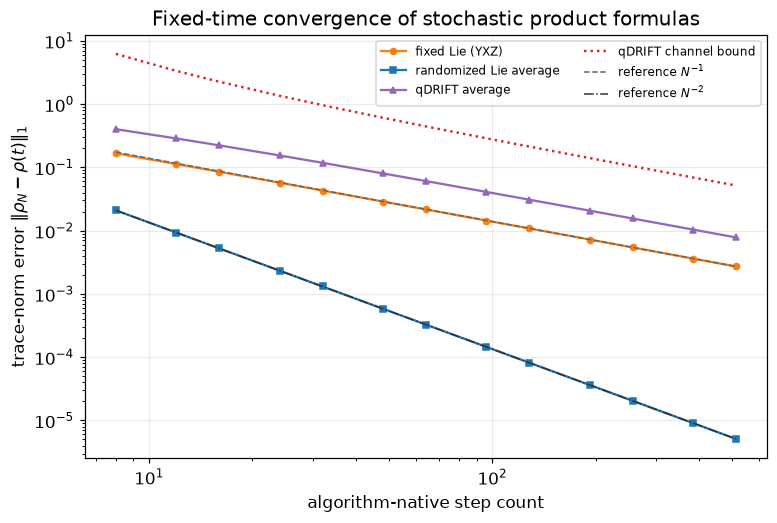

fixed Lie       : fitted tail slope = -0.998
randomized Lie  : fitted tail slope = -2.000
qDRIFT          : fitted tail slope = -0.990
qDRIFT state errors obey channel bound: True


In [2]:
total_time = 1.6
step_counts = np.array([8, 12, 16, 24, 32, 48, 64, 96, 128, 192, 256, 384, 512])
rho_exact = qu.exact_density_path(H, psi0, [total_time])[-1]

fixed_errors = np.array([
    qu.trace_norm_error(
        rt.fixed_lie_path(terms, rho0, total_time, int(steps), fixed_order)[-1],
        rho_exact,
    )
    for steps in step_counts
])
randomized_errors = np.array([
    qu.trace_norm_error(
        rt.randomized_lie_average_path(terms, rho0, total_time, int(steps))[-1],
        rho_exact,
    )
    for steps in step_counts
])
qdrift_errors = np.array([
    qu.trace_norm_error(
        qd.qdrift_average_path(h, qu.PAULIS, rho0, total_time, int(steps))[-1],
        rho_exact,
    )
    for steps in step_counts
])
qdrift_bounds = np.array([
    qd.qdrift_channel_bound(h, total_time, int(steps))
    for steps in step_counts
])

fig, ax = plt.subplots(figsize=(8.0, 5.0))
ax.loglog(step_counts, fixed_errors, "o-", ms=4, color="tab:orange", label="fixed Lie (YXZ)")
ax.loglog(step_counts, randomized_errors, "s-", ms=4, color="tab:blue", label="randomized Lie average")
ax.loglog(step_counts, qdrift_errors, "^-", ms=4, color="tab:purple", label="qDRIFT average")
ax.loglog(step_counts, qdrift_bounds, ":", lw=1.6, color="tab:red", label="qDRIFT channel bound")
reference_steps = step_counts.astype(float)
ax.loglog(reference_steps, fixed_errors[-1] * (reference_steps / reference_steps[-1])**-1,
          "--", lw=1.0, color="0.4", label=r"reference $N^{-1}$")
ax.loglog(reference_steps, randomized_errors[-1] * (reference_steps / reference_steps[-1])**-2,
          "-.", lw=1.0, color="0.2", label=r"reference $N^{-2}$")
ax.set(xlabel="algorithm-native step count",
       ylabel=r"trace-norm error $\|\rho_N-\rho(t)\|_1$",
       title="Fixed-time convergence of stochastic product formulas")
ax.legend(fontsize=8, ncol=2)
plt.show()

tail = slice(-6, None)
slopes = {
    "fixed Lie": np.polyfit(np.log(step_counts[tail]), np.log(fixed_errors[tail]), 1)[0],
    "randomized Lie": np.polyfit(np.log(step_counts[tail]), np.log(randomized_errors[tail]), 1)[0],
    "qDRIFT": np.polyfit(np.log(step_counts[tail]), np.log(qdrift_errors[tail]), 1)[0],
}
for label, slope in slopes.items():
    print(f"{label:16s}: fitted tail slope = {slope: .3f}")
print("qDRIFT state errors obey channel bound:", np.all(qdrift_errors <= qdrift_bounds))

## アニメーションの共通表示

左は物理的な Bloch 球、右は各時刻の厳密状態を原点とした局所誤差平面で、誤差を3倍に拡大する。右パネルの表示範囲は全フレーム・全標本から自動的に決める。

Randomized Trotter の step 間に挿入するフレームは、端点間の移動を見やすくする visual guide であり、追加の積公式 step ではない。qDRIFT は各 gate 適用後の端点をそのまま1フレームとして表示する。

In [3]:
def draw_bloch_sphere(ax):
    u = np.linspace(0, 2 * np.pi, 41)
    v = np.linspace(0, np.pi, 21)
    xs = np.outer(np.cos(u), np.sin(v))
    ys = np.outer(np.sin(u), np.sin(v))
    zs = np.outer(np.ones_like(u), np.cos(v))
    ax.plot_wireframe(xs, ys, zs, color="0.82", linewidth=0.35, alpha=0.55)
    ax.plot([-1, 1], [0, 0], [0, 0], color="0.72", linewidth=0.7)
    ax.plot([0, 0], [-1, 1], [0, 0], color="0.72", linewidth=0.7)
    ax.plot([0, 0], [0, 0], [-1, 1], color="0.72", linewidth=0.7)
    ax.text(1.08, 0, 0, "x")
    ax.text(0, 1.08, 0, "y")
    ax.text(0, 0, 1.08, "z")
    ax.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), zlim=(-1.1, 1.1))
    ax.set_box_aspect((1, 1, 1))
    ax.set_axis_off()
    ax.grid(False)


def state_paths_to_bloch(paths):
    flat = paths.reshape(-1, paths.shape[-1])
    vectors = np.array([qu.bloch(qu.density(state)) for state in flat])
    return vectors.reshape(paths.shape[:-1] + (3,))


def density_path_to_bloch(path):
    return np.array([qu.bloch(rho) for rho in path])


def interpolate_paths(boundary_paths, subframes, normalize=False):
    """Linearly interpolate the last-but-one axis between algorithm endpoints."""
    boundary_paths = np.asarray(boundary_paths, dtype=float)
    steps = boundary_paths.shape[-2] - 1
    result = np.empty(boundary_paths.shape[:-2] + (steps * subframes + 1, 3))
    for segment in range(steps):
        for offset in range(subframes):
            fraction = offset / subframes
            value = (
                (1 - fraction) * boundary_paths[..., segment, :]
                + fraction * boundary_paths[..., segment + 1, :]
            )
            if normalize:
                value = value / np.linalg.norm(value, axis=-1, keepdims=True)
            result[..., segment * subframes + offset, :] = value
    result[..., -1, :] = boundary_paths[..., -1, :]
    return result


def make_error_animation(sample_paths, exact_path, mean_path, times, title, fixed_path=None):
    error_zoom = 3.0
    frame_count = len(times)
    sample_errors = np.array([
        error_zoom * qu.local_error_coordinates(sample_paths[:, frame], exact_path[frame], hamiltonian_axis)
        for frame in range(frame_count)
    ])
    mean_errors = np.array([
        error_zoom * qu.local_error_coordinates(mean_path[[frame]], exact_path[frame], hamiltonian_axis)[0]
        for frame in range(frame_count)
    ])
    fixed_errors = None if fixed_path is None else np.array([
        error_zoom * qu.local_error_coordinates(fixed_path[[frame]], exact_path[frame], hamiltonian_axis)[0]
        for frame in range(frame_count)
    ])
    error_arrays = [sample_errors, mean_errors]
    if fixed_errors is not None:
        error_arrays.append(fixed_errors)
    error_limit = max(0.12, 1.12 * max(np.max(np.abs(values)) for values in error_arrays))

    fig = plt.figure(figsize=(10.8, 5.4), dpi=100)
    ax = fig.add_subplot(121, projection="3d")
    err_ax = fig.add_subplot(122)
    draw_bloch_sphere(ax)

    cloud = ax.scatter([], [], [], s=12, color="0.5", alpha=0.30, label="sampled circuits")
    single_line, = ax.plot([], [], [], color="tab:purple", lw=1.6, label="one random circuit")
    single_dot, = ax.plot([], [], [], "o", color="tab:purple", ms=6)
    exact_line, = ax.plot([], [], [], color="tab:red", lw=2.2, label="exact")
    exact_dot, = ax.plot([], [], [], "o", color="tab:red", ms=6)
    mean_line, = ax.plot([], [], [], color="tab:blue", lw=2.2, label="exact channel average")
    mean_dot, = ax.plot([], [], [], "o", color="tab:blue", ms=7)
    fixed_line = fixed_dot = None
    if fixed_path is not None:
        fixed_line, = ax.plot([], [], [], color="tab:orange", lw=2.0, label="fixed Lie (YXZ)")
        fixed_dot, = ax.plot([], [], [], "o", color="tab:orange", ms=6)
    ax.legend(loc="upper left", fontsize=7)

    error_cloud = err_ax.scatter([], [], s=16, color="0.5", alpha=0.32, label="sampled circuits")
    error_single = err_ax.scatter([], [], s=55, color="tab:purple", label="one random circuit", zorder=4)
    error_mean = err_ax.scatter([], [], s=75, color="tab:blue", label="exact channel average", zorder=6)
    error_fixed = None
    if fixed_path is not None:
        error_fixed = err_ax.scatter([], [], s=65, color="tab:orange", label="fixed Lie (YXZ)", zorder=5)
    err_ax.scatter(0, 0, marker="x", s=90, linewidth=2.2, color="tab:red", label="exact", zorder=7)
    err_ax.axhline(0, color="0.72", linewidth=0.8)
    err_ax.axvline(0, color="0.72", linewidth=0.8)
    err_ax.set(xlim=(-error_limit, error_limit), ylim=(-error_limit, error_limit), aspect="equal",
               xlabel=rf"$\times {error_zoom:g}$ orbit-tangent error",
               ylabel=rf"$\times {error_zoom:g}$ transverse error",
               title="Magnified error around the exact state")
    err_ax.legend(loc="upper right", fontsize=7)

    def update(frame):
        points = sample_paths[:, frame]
        cloud._offsets3d = (points[:, 0], points[:, 1], points[:, 2])
        one = sample_paths[0, :frame + 1]
        single_line.set_data_3d(one[:, 0], one[:, 1], one[:, 2])
        single_dot.set_data_3d([one[-1, 0]], [one[-1, 1]], [one[-1, 2]])
        exact = exact_path[:frame + 1]
        exact_line.set_data_3d(exact[:, 0], exact[:, 1], exact[:, 2])
        exact_dot.set_data_3d([exact[-1, 0]], [exact[-1, 1]], [exact[-1, 2]])
        mean = mean_path[:frame + 1]
        mean_line.set_data_3d(mean[:, 0], mean[:, 1], mean[:, 2])
        mean_dot.set_data_3d([mean[-1, 0]], [mean[-1, 1]], [mean[-1, 2]])
        if fixed_path is not None:
            fixed = fixed_path[:frame + 1]
            fixed_line.set_data_3d(fixed[:, 0], fixed[:, 1], fixed[:, 2])
            fixed_dot.set_data_3d([fixed[-1, 0]], [fixed[-1, 1]], [fixed[-1, 2]])
            error_fixed.set_offsets(fixed_errors[[frame]])
        error_cloud.set_offsets(sample_errors[frame])
        error_single.set_offsets(sample_errors[frame, [0]])
        error_mean.set_offsets(mean_errors[[frame]])
        fig.suptitle(f"{title}: t = {times[frame]:.2f}")

    animation = FuncAnimation(fig, update, frames=frame_count, interval=150, blit=False, repeat=True)
    plt.close(fig)
    return animation

## Randomized Lie--Trotter

各区間で $3!=6$ 通りの適用順序から一つを一様に選ぶ。オレンジは固定順序 $Y\to X\to Z$、青は6候補を各区間で厳密に平均した状態、紫と灰色は実際に得られうるランダム回路である。

In [4]:
randomized_time = 2.0
randomized_steps = 6
randomized_subframes = 5
randomized_samples = 180

randomized_sample_states = rt.sample_randomized_lie_paths(
    terms, psi0, randomized_time, randomized_steps, randomized_samples,
    np.random.default_rng(SEED + 1),
)
randomized_sample_boundaries = state_paths_to_bloch(randomized_sample_states)
randomized_mean_boundaries = density_path_to_bloch(
    rt.randomized_lie_average_path(terms, rho0, randomized_time, randomized_steps)
)
randomized_fixed_boundaries = density_path_to_bloch(
    rt.fixed_lie_path(terms, rho0, randomized_time, randomized_steps, fixed_order)
)
randomized_sample_display = interpolate_paths(
    randomized_sample_boundaries, randomized_subframes, normalize=True
)
randomized_mean_display = interpolate_paths(randomized_mean_boundaries, randomized_subframes)
randomized_fixed_display = interpolate_paths(
    randomized_fixed_boundaries, randomized_subframes, normalize=True
)
randomized_times = np.linspace(
    0, randomized_time, randomized_steps * randomized_subframes + 1
)
randomized_exact_display = density_path_to_bloch(
    qu.exact_density_path(H, psi0, randomized_times)
)
randomized_animation = make_error_animation(
    randomized_sample_display, randomized_exact_display, randomized_mean_display,
    randomized_times, "Randomized Lie--Trotter (r = 6)", randomized_fixed_display,
)
display(HTML(randomized_animation.to_jshtml()))

## qDRIFT

qDRIFT は各 step で $j$ を $p_j=|h_j|/\lambda$ に従って独立に選び、$\exp[-i(\lambda t/N)\,\mathrm{sgn}(h_j)P_j]$ を適用する。青は3候補を確率 $p_j$ で厳密に平均した状態、紫と灰色はランダム回路である。平均 Bloch ベクトルが球の内側へ縮むのは、異なる純粋状態を古典混合したためである。

In [5]:
qdrift_time = 2.0
qdrift_steps = 40
qdrift_samples = 140
qdrift_times = np.linspace(0, qdrift_time, qdrift_steps + 1)

qdrift_sample_states = qd.sample_qdrift_paths(
    h, qu.PAULIS, psi0, qdrift_time, qdrift_steps, qdrift_samples,
    np.random.default_rng(SEED + 2),
)
qdrift_sample_display = state_paths_to_bloch(qdrift_sample_states)
qdrift_mean_display = density_path_to_bloch(
    qd.qdrift_average_path(h, qu.PAULIS, rho0, qdrift_time, qdrift_steps)
)
qdrift_exact_display = density_path_to_bloch(
    qu.exact_density_path(H, psi0, qdrift_times)
)
qdrift_animation = make_error_animation(
    qdrift_sample_display, qdrift_exact_display, qdrift_mean_display,
    qdrift_times, "qDRIFT (N = 40)",
)
display(HTML(qdrift_animation.to_jshtml()))

## 解釈と数値チェック

Randomized Trotter と qDRIFT の理論保証は、ランダム列を忘れた**平均チャネル**に対するものである。紫の単一回路には回路サンプリングの揺らぎがあり、実験で観測量を推定するときはさらに measurement shot noise が加わる。平均チャネル誤差、単一回路の典型誤差、有限 run の推定誤差を区別する必要がある。

In [6]:
def assert_density_matrix(rho, atol=2e-12):
    assert np.allclose(rho, rho.conj().T, atol=atol)
    assert np.isclose(np.trace(rho), 1.0, atol=atol)
    assert np.min(np.linalg.eigvalsh(rho)) >= -atol
    assert np.linalg.norm(qu.bloch(rho)) <= 1 + atol

assert_density_matrix(rt.randomized_lie_average_path(
    terms, rho0, randomized_time, randomized_steps
)[-1])
assert_density_matrix(qd.qdrift_average_path(
    h, qu.PAULIS, rho0, qdrift_time, qdrift_steps
)[-1])
assert np.allclose(np.linalg.norm(randomized_sample_states, axis=2), 1.0)
assert np.allclose(np.linalg.norm(qdrift_sample_states, axis=2), 1.0)
assert -1.2 < slopes["fixed Lie"] < -0.8
assert -2.2 < slopes["randomized Lie"] < -1.8
assert -1.2 < slopes["qDRIFT"] < -0.8
assert np.all(qdrift_errors <= qdrift_bounds + 1e-12)
print("All checks passed.")
print(f"Randomized final mean Bloch radius: {np.linalg.norm(randomized_mean_boundaries[-1]):.6f}")
print(f"qDRIFT final mean Bloch radius:      {np.linalg.norm(qdrift_mean_display[-1]):.6f}")

All checks passed.
Randomized final mean Bloch radius: 0.983337
qDRIFT final mean Bloch radius:      0.849920
